# ABL1 (P00519) Ki datasets

Single-target preprocessing pipeline, same structure as `fxa_solubility_logd.ipynb`, applied to two independent Papyrus-derived Ki datasets. Each target column is `pchembl_value_Mean`, renamed to `Target` at Step 0.

Splitting uses `create_n_stratified_train_val_test_splits` (single-readout stratified train/val/test splitter) rather than the multi-readout splitter used in the LogD/logS example, since each dataset here has one target, not two jointly-stratified readouts.

In [ ]:
import os
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from mol_faith.data.create_dataset.create_stratified_data_splits import (
    create_n_stratified_train_val_test_splits,
)
from mol_faith.data.data_managers.smiles_data_manager import SMILESTokenizer
from mol_faith.data.data_managers.tokenization_helper import test_round_trip_fidelity
from mol_faith.data.preprocessing.clean_data import clean_molecular_data
from mol_faith.data.preprocessing.filter_data import filter_molecular_data


In [2]:
def plot_splits(base_output_path, target_column_index, xlabel='Target Value'):
    split_folders = sorted(glob(os.path.join(base_output_path, 'data_split_*')))
    num_splits = len(split_folders)

    fig, axes = plt.subplots(nrows=num_splits, ncols=1, figsize=(10, 4 * num_splits))
    for i, split_folder in enumerate(split_folders):
        train_df = pd.read_csv(os.path.join(split_folder, 'train.csv'))
        val_df = pd.read_csv(os.path.join(split_folder, 'val.csv'))
        test_df = pd.read_csv(os.path.join(split_folder, 'test.csv'))

        train_values = train_df.iloc[:, target_column_index]
        val_values = val_df.iloc[:, target_column_index]
        test_values = test_df.iloc[:, target_column_index]

        ax = axes[i] if num_splits > 1 else axes
        sns.kdeplot(train_values, color='blue', linewidth=2, label='Train', ax=ax)
        sns.kdeplot(val_values, color='orange', linewidth=2, linestyle='dashed', label='Validation', ax=ax)
        sns.kdeplot(test_values, color='red', linewidth=2, linestyle='dotted', label='Test', ax=ax)

        ax.set_title(f'Split {i+1}')
        ax.set_xlabel(xlabel)
        ax.set_ylabel('Density')
        ax.legend()

    plt.tight_layout()
    plt.show()

# Process ABL1 dataset

In [3]:
SOURCE_DATA_PATH = Path("../../../data/real_world/ABL1_pki/all_data.csv")

SMILES_COLUMN = "SMILES"
TARGET_COLUMN = "pchembl_value_Mean"

# Everything the pipeline produces lands here, mirroring the MolFaith `data/` layout.
DATA_DIR = Path("../../../data/real_world/ABL1_pki")

RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

CLEANED_DIR = DATA_DIR / "cleaned"
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

FILTERED_DIR = DATA_DIR / "cleaned_and_filtered"
FILTERED_DIR.mkdir(parents=True, exist_ok=True)

RAW_DATA_PATH = RAW_DIR / "raw_data.csv"
CLEANED_DATA_PATH = CLEANED_DIR / "cleaned_data.csv"
FILTERED_DATA_PATH = FILTERED_DIR / "filtered_data.csv"
VOCAB_PATH = FILTERED_DIR / "tokenizer_vocab.txt"
SPLITS_DIR = DATA_DIR / "data_splits"

assert SOURCE_DATA_PATH.exists(), SOURCE_DATA_PATH

## Step 0 - Reduce to SMILES + Target, and sanity-check the activity type

This dataset was built in `check_dataset.ipynb` via `keep_type(data, activity_types=['Ki'])`, so every row should already be Ki-only. That assumption is checked explicitly below rather than just assumed: `type_IC50`, `type_EC50` and `type_KD` must all be 0.

In [4]:
source_df = pd.read_csv(SOURCE_DATA_PATH)
print(f"{len(source_df)} rows in the source file")

for col in ("type_IC50", "type_EC50", "type_KD"):
    assert (source_df[col] == 0).all(), f"{col} has non-zero rows -- dataset is not Ki-only"
assert (source_df["type_Ki"] == 1).all(), "not every row is flagged type_Ki"
print("Confirmed: all rows are Ki-only (type_IC50/EC50/KD all 0, type_Ki all 1)")

raw_df = source_df[[SMILES_COLUMN, TARGET_COLUMN]].dropna().reset_index(drop=True)
raw_df = raw_df.rename(columns={TARGET_COLUMN: "Target"})

print(f"{len(source_df)} -> {len(raw_df)} rows after selecting SMILES + {TARGET_COLUMN} and dropping NaNs")
display(raw_df.describe())
raw_df.head()

1368 rows in the source file
Confirmed: all rows are Ki-only (type_IC50/EC50/KD all 0, type_Ki all 1)
1368 -> 1368 rows after selecting SMILES + pchembl_value_Mean and dropping NaNs


,Target
count,1368.000000
mean,7.021526
std,1.401799
min,4.100000
25%,6.200000
50%,6.290000
75%,8.104000
max,10.730000


,SMILES,Target
0,O=C(Nc1nnc(SCc2ccc([N+](=O)[O-])cc2)s1)c1ccccc1Cl,7.080
1,O=C(Nc1cc2ccc(-c3cc(CO)ccc3Cl)cc2cn1)C1CC1,9.700
2,NC(=O)c1ccc2nc(-c3ccc([N+]([O])=O)o3)cn2c1,6.400
3,Fc1ccc(C(Cl)Cn2ncc3c(Nc4cccc(F)c4)ncnc32)cc1,5.908
4,Nc1nccc2scc(-c3ccc(NC(=O)Nc4ccccc4C(F)(F)F)cc3...,6.200


In [5]:
# SMILES must stay the first column: GraphDataManager reads it positionally.
raw_df.to_csv(RAW_DATA_PATH, index=False)
print(f"written to: {RAW_DATA_PATH}")
print(f"columns: {raw_df.columns.tolist()}")

written to: /home/marcelhiltscher/Documents/Datasets/Faithfulness_Test/P00519_WT_ABL1/raw/raw_data.csv
columns: ['SMILES', 'Target']


## Step 1 - Cleaning

Writes `cleaned_data.csv`, `cleaning_summary.csv` and - if anything fails - `failed_cleaning.csv` / `duplicates.csv` into `CLEANED_DIR`.

In [6]:
clean_molecular_data(
    dataset_path=str(RAW_DATA_PATH),
    output_path=str(CLEANED_DIR),
)

INFO:mol_faith.data.preprocessing.clean_data:Loading dataset from /home/marcelhiltscher/Documents/Datasets/Faithfulness_Test/P00519_WT_ABL1/raw/raw_data.csv
INFO:mol_faith.data.preprocessing.clean_data:Starting cleaning process for 1368 molecules
Cleaning SMILES:   0%|          | 0/1368 [00:00<?, ?it/s]INFO:mol_faith.data.preprocessing.clean_data:Processing O=C(Nc1nnc(SCc2ccc([N+](=O)[O-])cc2)s1)c1ccccc1Cl
[16:58:29] Initializing MetalDisconnector
[16:58:29] Running MetalDisconnector
[16:58:29] Initializing Normalizer
[16:58:29] Running Normalizer
[16:58:29] Running Uncharger
INFO:mol_faith.data.preprocessing.clean_data:Processing O=C(Nc1cc2ccc(-c3cc(CO)ccc3Cl)cc2cn1)C1CC1
[16:58:29] Initializing MetalDisconnector
[16:58:29] Running MetalDisconnector
[16:58:29] Initializing Normalizer
[16:58:29] Running Normalizer
[16:58:29] Running Uncharger
INFO:mol_faith.data.preprocessing.clean_data:Processing NC(=O)c1ccc2nc(-c3ccc([N+]([O])=O)o3)cn2c1
[16:58:29] Initializing MetalDisconnector
[16:

In [7]:
for report in ("cleaning_summary.csv", "failed_cleaning.csv", "duplicates.csv"):
    path = CLEANED_DIR / report
    if path.exists():
        print(f"\n{report}:")
        display(pd.read_csv(path).head())

cleaned_df = pd.read_csv(CLEANED_DATA_PATH)
print(f"\n{len(cleaned_df)} molecules after cleaning, columns {cleaned_df.columns.tolist()}")


cleaning_summary.csv:


,original_molecules,failed_cleaning,duplicates_removed,final_cleaned_molecules,cleaning_success_rate,final_retention_rate
0,1368,0,0,1368,100.00%,100.00%



1368 molecules after cleaning, columns ['SMILES', 'Target']


## Step 2 - Filtering

Same cutoffs as the other MolFaith datasets.

In [8]:
MAX_SEQUENCE_LENGTH = 100
MAX_HEAVY_ATOMS = 50

filter_molecular_data(
    input_data_path=str(CLEANED_DATA_PATH),
    output_dir=str(FILTERED_DIR),
    max_sequence_length=MAX_SEQUENCE_LENGTH,
    max_heavy_atoms=MAX_HEAVY_ATOMS,
)

INFO:mol_faith.data.preprocessing.filter_data:Loading data from /home/marcelhiltscher/Documents/Datasets/Faithfulness_Test/P00519_WT_ABL1/cleaned/cleaned_data.csv
INFO:mol_faith.data.preprocessing.filter_data:Loaded 1368 molecules
INFO:mol_faith.data.preprocessing.filter_data:Applying molecular filters to 1368 molecules...
INFO:mol_faith.data.preprocessing.filter_data:  - Max sequence length: 100
INFO:mol_faith.data.preprocessing.filter_data:  - Max heavy atoms: 50
Applying filters: 100%|██████████| 1368/1368 [00:00<00:00, 7551.34it/s]
INFO:mol_faith.data.preprocessing.filter_data:Filtering results:
INFO:mol_faith.data.preprocessing.filter_data:  - Input molecules: 1368
INFO:mol_faith.data.preprocessing.filter_data:  - Passed filters: 1366 (99.9%)
INFO:mol_faith.data.preprocessing.filter_data:  - Rejected: 2 (0.1%)
INFO:mol_faith.data.preprocessing.filter_data:Filtered data saved to: /home/marcelhiltscher/Documents/Datasets/Faithfulness_Test/P00519_WT_ABL1/cleaned_and_filtered/filtered

## Step 3 - Check tokenizer

In [9]:
tokenizer = SMILESTokenizer()
clean_and_filtered_data = pd.read_csv(FILTERED_DATA_PATH)
tokenizer.build_vocab_from_corpus(clean_and_filtered_data['SMILES'].tolist())
test_round_trip_fidelity(tokenizer, clean_and_filtered_data['SMILES'].tolist(), max_length=100)

INFO:mol_faith.data.data_managers.smiles_data_manager:Building vocabulary from 1366 SMILES strings
INFO:mol_faith.data.data_managers.smiles_data_manager:Built vocabulary with 31 tokens


Testing all 1366 SMILES
Testing encode-decode round-trip fidelity...

ROUND-TRIP FIDELITY TEST RESULTS
Total SMILES tested: 1366
Perfect matches: 1366 (100.00%)
🎉 PERFECT FIDELITY! All SMILES round-tripped correctly.


{'total_tested': 1366,
 'perfect_matches': 1366,
 'failed_roundtrips': [],
 'truncation_losses': [],
 'tokenization_failures': [],
 'unknown_token_issues': [],
 'success_rate': 1.0,
 'perfect_success_rate': 1.0,
 'failure_breakdown': {'truncation_losses': 0,
  'unknown_token_issues': 0,
  'other_failures': 0,
  'tokenization_failures': 0}}

In [10]:
tokenizer.save_vocab(VOCAB_PATH)

INFO:mol_faith.data.data_managers.smiles_data_manager:Saved chemical subword vocabulary to /home/marcelhiltscher/Documents/Datasets/Faithfulness_Test/P00519_WT_ABL1/cleaned_and_filtered/tokenizer_vocab.txt


## Step 4 - Create data splits

Single target, so `create_n_stratified_train_val_test_splits` (Freedman-Diaconis binning, `StratifiedShuffleSplit`) is used instead of the multi-readout joint-quantile splitter -- same convention as the other single-target MolFaith datasets (`FXA/`, `chembl2971_JAK2/`, `chembl4005_PIK3CA/`).

In [ ]:
# create_n_stratified_train_val_test_splits(
#     data_path=str(FILTERED_DATA_PATH),
#     base_output_path=str(SPLITS_DIR),
#     num_splits=5,
#     bin_method='fd',
#     input_column_index=0,
#     target_column_index=1,
# )

## Step 5 - Check the splits

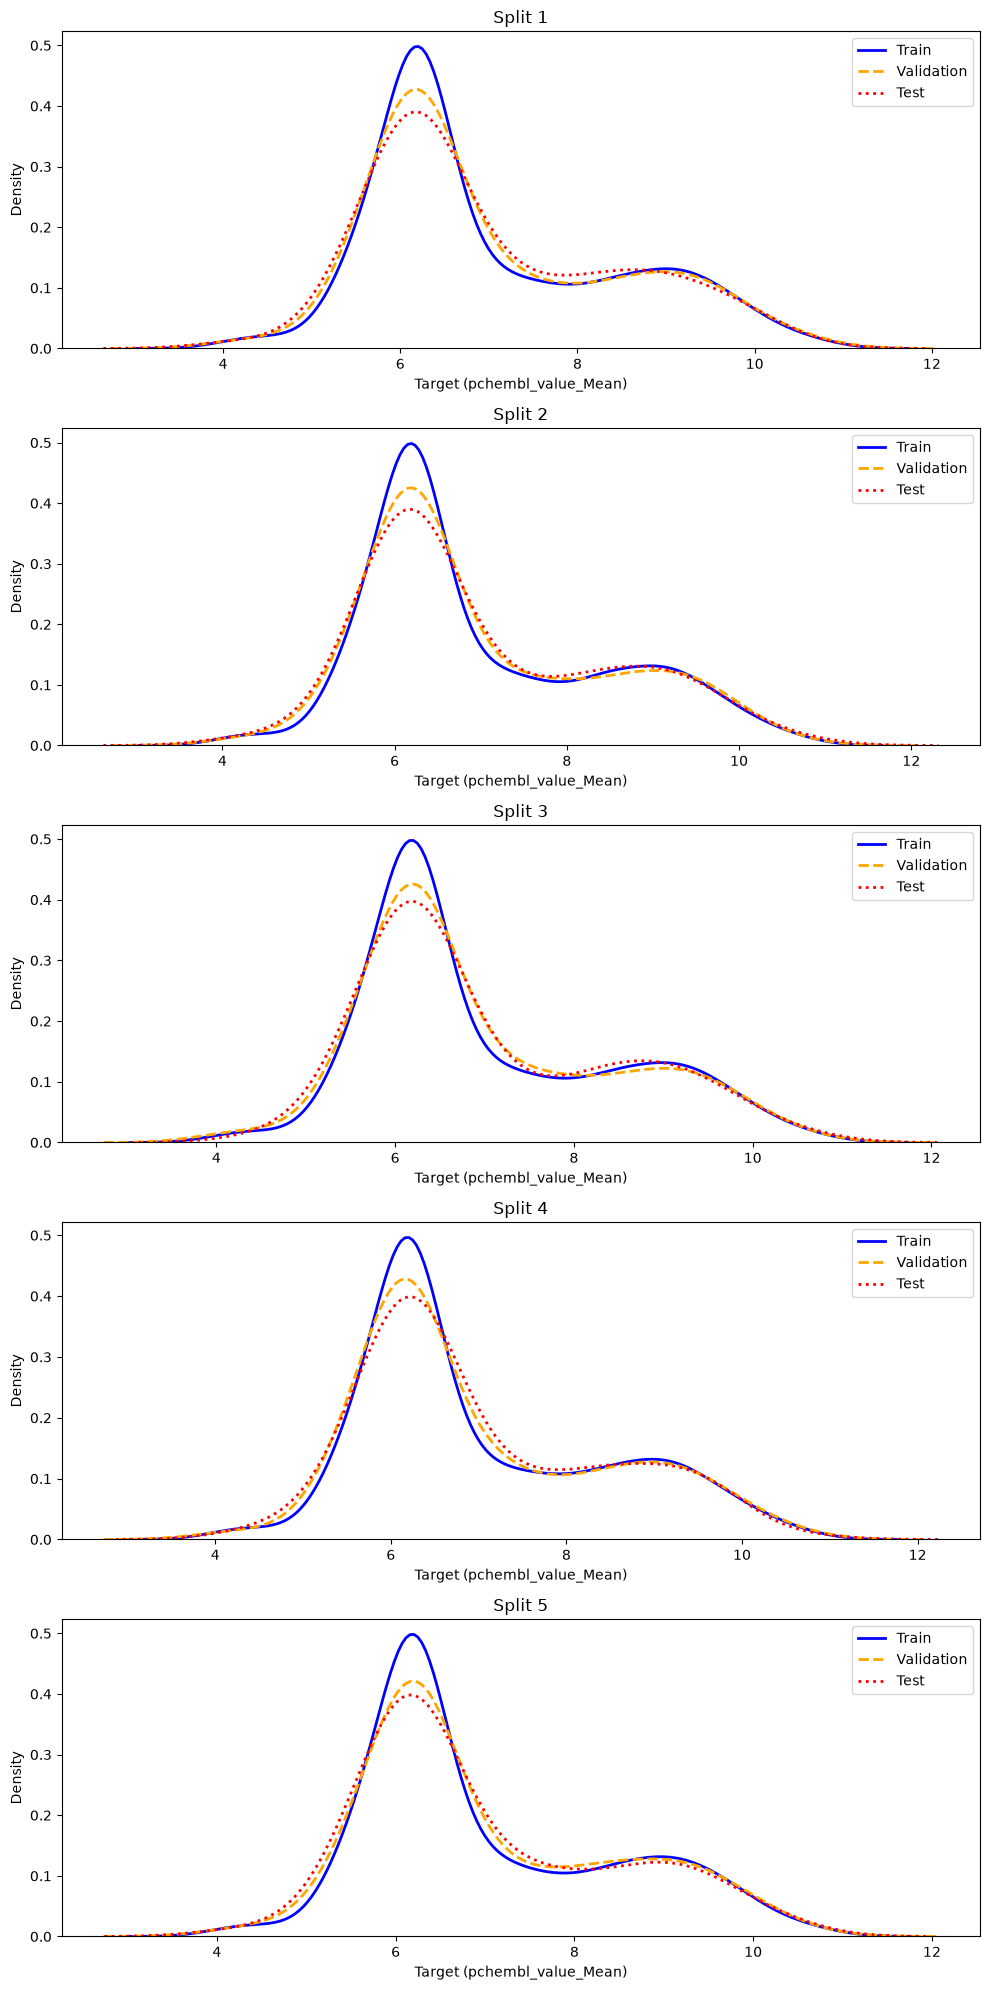

In [12]:
plot_splits(str(SPLITS_DIR), target_column_index=1, xlabel='Target (pchembl_value_Mean)')